In [ ]:
# Importación de librerías

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
# Definición del algoritmo propio de KNN

class KNN_Classifier:
    def __init__(self, k):
        self.k = k
        self.xInstancias = None
        self.yInstancias = None

    def distanciaEuclidiana(self, vector1, vector2):
        return np.sqrt(np.sum((vector1 - vector2)**2))

    def crearInstancia(self,xInstancias,yInstancias):
        self.xInstancias = xInstancias
        self.yInstancias = yInstancias

    def predicir(self,ds_x):
      x = np.array(ds_x)
      y_pred = [self.predecirFeature(i) for i in x]
      return np.array(y_pred)

    def predecirFeature(self,x):
      distancia = [self.distanciaEuclidiana(x, i) for i in self.xInstancias]
      topKVecinos = np.argsort(distancia)[:self.k]

      return np.bincount(self.yInstancias[topKVecinos]).argmax()





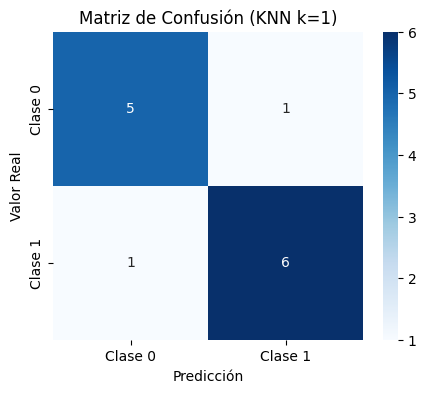

Reporte de Clasificación:

              precision    recall  f1-score   support

           0     0.8333    0.8333    0.8333         6
           1     0.8571    0.8571    0.8571         7

    accuracy                         0.8462        13
   macro avg     0.8452    0.8452    0.8452        13
weighted avg     0.8462    0.8462    0.8462        13



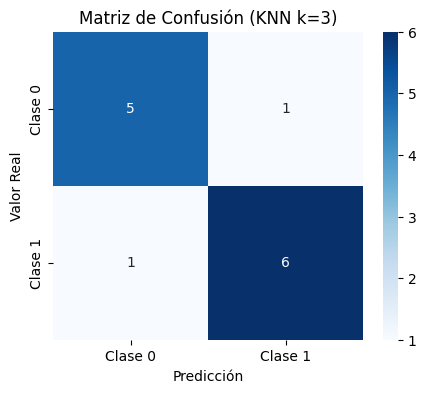

Reporte de Clasificación:

              precision    recall  f1-score   support

           0     0.8333    0.8333    0.8333         6
           1     0.8571    0.8571    0.8571         7

    accuracy                         0.8462        13
   macro avg     0.8452    0.8452    0.8452        13
weighted avg     0.8462    0.8462    0.8462        13



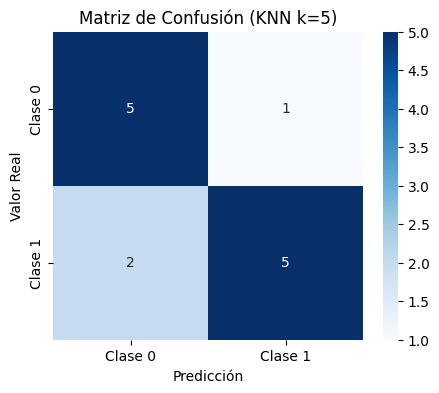

Reporte de Clasificación:

              precision    recall  f1-score   support

           0     0.7143    0.8333    0.7692         6
           1     0.8333    0.7143    0.7692         7

    accuracy                         0.7692        13
   macro avg     0.7738    0.7738    0.7692        13
weighted avg     0.7784    0.7692    0.7692        13



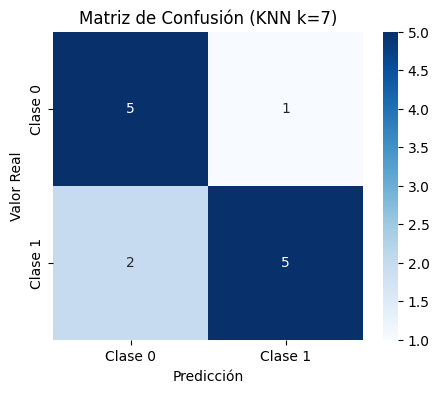

Reporte de Clasificación:

              precision    recall  f1-score   support

           0     0.7143    0.8333    0.7692         6
           1     0.8333    0.7143    0.7692         7

    accuracy                         0.7692        13
   macro avg     0.7738    0.7738    0.7692        13
weighted avg     0.7784    0.7692    0.7692        13



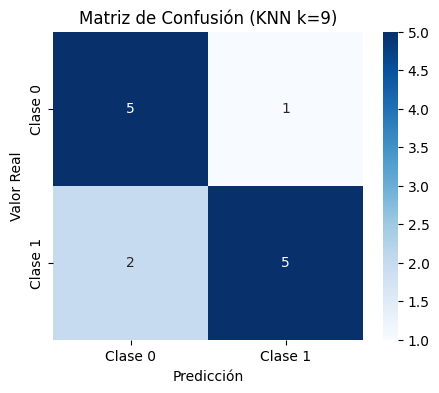

Reporte de Clasificación:

              precision    recall  f1-score   support

           0     0.7143    0.8333    0.7692         6
           1     0.8333    0.7143    0.7692         7

    accuracy                         0.7692        13
   macro avg     0.7738    0.7738    0.7692        13
weighted avg     0.7784    0.7692    0.7692        13



In [ ]:
from sklearn.model_selection import train_test_split

ds = pd.read_csv("/content/Dataset v1.0.csv")
X = ds.drop(columns=['Lugar', 'Target']).values.astype(float)
y = ds['Target'].values.astype(int)

x_train,x_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

# Ciclo for para evaluar el rendimiento de KNN para k = 1, 3, 5, 7 y 9

for i in range(1, 11, 2):

  modeloKNN = KNN_Classifier(k=i )
  modeloKNN.xInstancias = x_train
  modeloKNN.yInstancias = y_train

  y_pred = modeloKNN.predicir(x_test)

  import matplotlib.pyplot as plt
  import seaborn as sns
  from sklearn.metrics import classification_report, confusion_matrix

  cm = confusion_matrix(y_test, y_pred)

  plt.figure(figsize=(5, 4))
  sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Clase 0', 'Clase 1'],
            yticklabels=['Clase 0', 'Clase 1'])
  plt.title(f'Matriz de Confusión (KNN k={i})')
  plt.xlabel('Predicción')
  plt.ylabel('Valor Real')
  plt.show()


  print("Reporte de Clasificación:\n")
  print(classification_report(y_test, y_pred, digits=4))




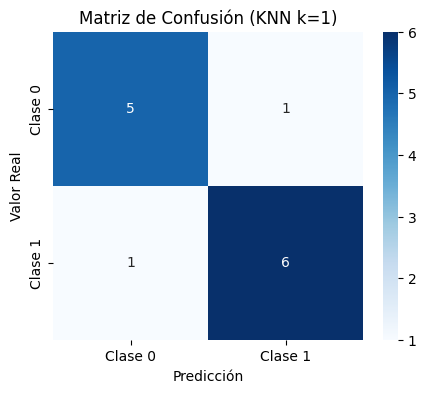

Reporte de Clasificación:

              precision    recall  f1-score   support

           0     0.8333    0.8333    0.8333         6
           1     0.8571    0.8571    0.8571         7

    accuracy                         0.8462        13
   macro avg     0.8452    0.8452    0.8452        13
weighted avg     0.8462    0.8462    0.8462        13



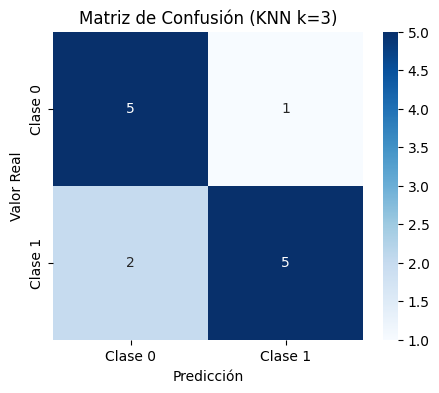

Reporte de Clasificación:

              precision    recall  f1-score   support

           0     0.7143    0.8333    0.7692         6
           1     0.8333    0.7143    0.7692         7

    accuracy                         0.7692        13
   macro avg     0.7738    0.7738    0.7692        13
weighted avg     0.7784    0.7692    0.7692        13



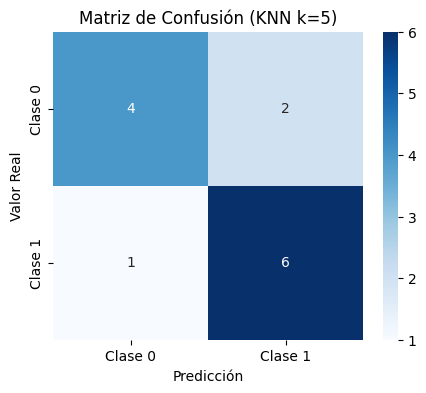

Reporte de Clasificación:

              precision    recall  f1-score   support

           0     0.8000    0.6667    0.7273         6
           1     0.7500    0.8571    0.8000         7

    accuracy                         0.7692        13
   macro avg     0.7750    0.7619    0.7636        13
weighted avg     0.7731    0.7692    0.7664        13



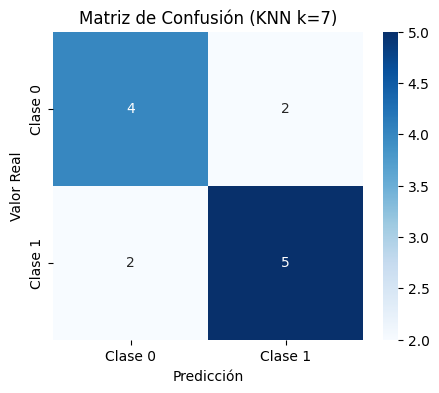

Reporte de Clasificación:

              precision    recall  f1-score   support

           0     0.6667    0.6667    0.6667         6
           1     0.7143    0.7143    0.7143         7

    accuracy                         0.6923        13
   macro avg     0.6905    0.6905    0.6905        13
weighted avg     0.6923    0.6923    0.6923        13



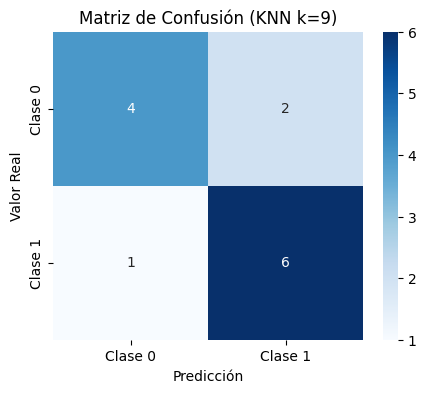

Reporte de Clasificación:

              precision    recall  f1-score   support

           0     0.8000    0.6667    0.7273         6
           1     0.7500    0.8571    0.8000         7

    accuracy                         0.7692        13
   macro avg     0.7750    0.7619    0.7636        13
weighted avg     0.7731    0.7692    0.7664        13



In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Ciclo para probar el algoritmo de KNN de scikit learn para
# k = 1, 3, 5, 7 y 9

for i in range(1, 11, 2):
  modelKNN = KNeighborsClassifier(n_neighbors=i)
  modelKNN.fit(x_train, y_train)
  y_pred = modelKNN.predict(x_test)
  import matplotlib.pyplot as plt
  import seaborn as sns
  from sklearn.metrics import classification_report, confusion_matrix

  cm = confusion_matrix(y_test, y_pred)

  plt.figure(figsize=(5, 4))
  sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
              xticklabels=['Clase 0', 'Clase 1'],
              yticklabels=['Clase 0', 'Clase 1'])
  plt.title(f'Matriz de Confusión (KNN k={i})')
  plt.xlabel('Predicción')
  plt.ylabel('Valor Real')
  plt.show()
  print("Reporte de Clasificación:\n")
  print(classification_report(y_test, y_pred, digits=4))





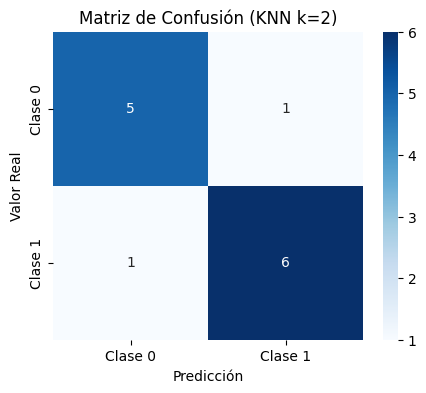

Reporte de Clasificación:

              precision    recall  f1-score   support

           0     0.8333    0.8333    0.8333         6
           1     0.8571    0.8571    0.8571         7

    accuracy                         0.8462        13
   macro avg     0.8452    0.8452    0.8452        13
weighted avg     0.8462    0.8462    0.8462        13



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Clase 0', 'Clase 1'],
            yticklabels=['Clase 0', 'Clase 1'])
plt.title('Matriz de Confusión (KNN k=2)')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.show()


print("Reporte de Clasificación:\n")
print(classification_report(y_test, y_pred, digits=4))

# RANDOM FOREST

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Entrenamiento del Random Forest

modelRF = RandomForestClassifier(n_estimators=100, random_state=42)
modelRF.fit(x_train, y_train)
y_pred = modelRF.predict(x_test)

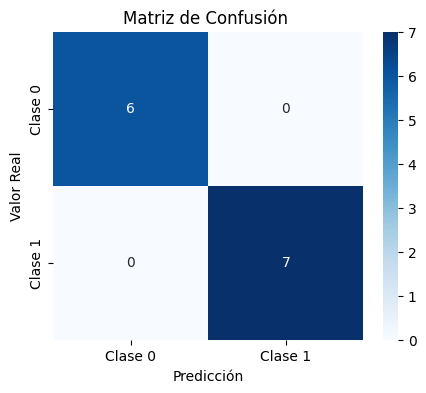

Reporte de Clasificación:

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000         6
           1     1.0000    1.0000    1.0000         7

    accuracy                         1.0000        13
   macro avg     1.0000    1.0000    1.0000        13
weighted avg     1.0000    1.0000    1.0000        13



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Evaluación del Random Forest

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Clase 0', 'Clase 1'],
            yticklabels=['Clase 0', 'Clase 1'])
plt.title('Matriz de Confusión ')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.show()


print("Reporte de Clasificación:\n")
print(classification_report(y_test, y_pred, digits=4))